In [1]:
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import matplotlib as mpl

import numpy as np

# Introduction
A short tutorial notebook on using colors in Matplotlib.
It has two parts. The first part covers how colors are represented in Matplotlib and a few ways to use them.
The second part is dedicated to colormap objects, which map numerical values to colors.

## A - Colors in Matplotlib
Matplotlib uses red, green and blue (RGB) as primary colors. By mixing these three colors in different proportions, all the other colors can be reconstructed.
This color triplet can be represented in two ways:
- As a tuple (r,g,b) of three numbers in the interval [0,1] (e.g. (1,0,0) for red)
- As a hexadecimal value (e.g. #FF0000 for red)



We will regularly use the function below to visualize colors:



In [2]:
def show_color(colors_lists, lists_name = None, title = 'Color Representation') :
    """ 
    This function show lists of colors provided as input. 
    Each list is dispayed in a row and its corresponding colors in columns.
    colors_lists: a two dimensional list of colors to show
    lists_name : text to label rows"""
    
    # number of list to show
    num_list = len(colors_lists)

    yticks_name = []
    if lists_name == None :
        yticks_name = ['list ' + str(i) for i in range(num_list)]
    else :
        yticks_name = lists_name.copy()
    
    fig, ax = plt.subplots(figsize=(6.0, 2.0), layout='constrained')
    
    for i,color_list in enumerate(colors_lists):
        colors_number = len(color_list)
        x = np.arange(colors_number)
        y = np.full_like(x,i)
        ax.scatter(x,y,c=color_list,s=200, edgecolor='dimgray',zorder=2)
        if colors_number == 1:
            hex_val = mpl.colors.to_hex(color_list[0])
            yticks_name[i] = yticks_name[i] + '\n' + str(hex_val)

    ax.set_xticks([])
    ax.set_yticks(range(num_list),yticks_name)
    ax.tick_params(left=False)
    ax.grid(visible=True)
    ax.spines[:].set_visible(False)
    ax.set_ylim([-0.5, num_list - 0.5])
    ax.yaxis.set_inverted(True)
    
    plt.title(title)

In [3]:
def compute_color_variation(input_color,input_param = "val"):
    """
    Compute variations of the provided colors depending on the parameter input (eg Value).
    Others parameters are keep constant (eg Saturation and Hue).
    Return a list with colors variation in rgb tuple format"""
    
    assert input_param in ["val","sat","hue"], "input_param must be among hue, sat, val !"
    
    input_rgb = mpl.colors.to_rgb(input_color)
    hue, sat, val = mpl.colors.rgb_to_hsv(input_rgb)
    
    step_list = np.arange(0.1,1.1,0.1)
    
    if input_param == 'sat':
        hsv_list = [(hue,x,val) for x in step_list]
    else :
        if input_param == 'val':
            hsv_list = [(hue,sat,x) for x in step_list]
        else :
            hsv_list = [(x,sat,val) for x in step_list]
    
    hsv_array = np.array(hsv_list)
    return [mpl.colors.hsv_to_rgb(color) for color in hsv_array]


In [4]:
def get_complementary_color(input_color):
    """
    Return rgb complementary color of input_color.
    Complementary is just adding Hue 0.5 mod 1 (keeping saturation and value)."""
    
    input_rgb = mpl.colors.to_rgb(input_color)
    hsv = mpl.colors.rgb_to_hsv(input_rgb)
    hue = hsv[0]
    
    compl_hue = hue + 0.5
    if compl_hue > 1.0 :
        compl_hue = compl_hue - 1.0
    hsv[0] = compl_hue
    compl_rgb = mpl.colors.hsv_to_rgb(hsv)
    return compl_rgb


Below is an example of RGB color representation.
As you can see, you can either enter the numerical values directly or use conversion functions with the color names defined in Matplotlib (see the documentation).

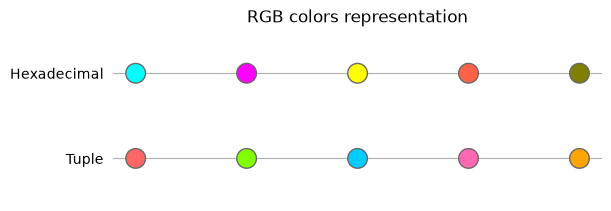

In [5]:
hex_defined_color = ['#0ff','#f0f', '#ff0', mpl.colors.to_hex('tomato'),mpl.colors.to_hex('olive')]
tuple_defined_color = [(1.0,0.4,0.4),(0.5,1,0),(0,0.8,1),mpl.colors.to_rgb('hotpink'),mpl.colors.to_rgb('orange')]

colors_lists = [hex_defined_color, tuple_defined_color]
colors_list_name = ['Hexadecimal','Tuple']

show_color(colors_lists,colors_list_name,title="RGB colors representation")
plt.show()

Basic colors (red, green...) can even be called by a single letter.
Below are the basic colors, their one-letter shortcuts and a few extended colors.

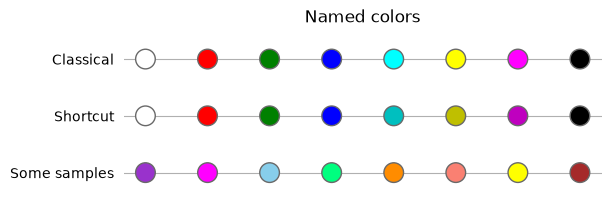

In [6]:
basic_named_color = ['white','red','green', 'blue','cyan', 'yellow', 'magenta', 'black']
letter_named_color = ['w','r','g', 'b','c', 'y', 'm', 'k']
some_named_color = ['darkorchid','fuchsia','skyblue', 'springgreen','darkorange', 'salmon', 'yellow', 'brown']

colors_lists = [basic_named_color,letter_named_color, some_named_color]
colors_list_name = ['Classical','Shortcut','Some samples']

show_color(colors_lists,colors_list_name,title="Named colors")
plt.show()

As you can see in the first two rows, the basic colors and their shortcut versions do not always match. This concerns cyan, magenta and yellow.

#### HSV representation
A color can also be described by its HSV value, which is a tuple with the same structure as the RGB tuple: three numbers between 0 and 1.
- Hue (H) is the tint. It corresponds to what we usually have in mind when we talk about color (red, green, orange...).
- Saturation (S) corresponds to the purity of the color. A highly saturated color is bright and intense, while a less saturated color is more pastel.
- Value (V) is the brightness, the luminosity of the color (light or dark).

In the end, "color" can mean either the set of parameters describing a color (HSV) or only the hue (H), which sometimes leads to misunderstandings...

In the example below, we vary the hue of the "color" red while keeping the saturation and brightness identical.

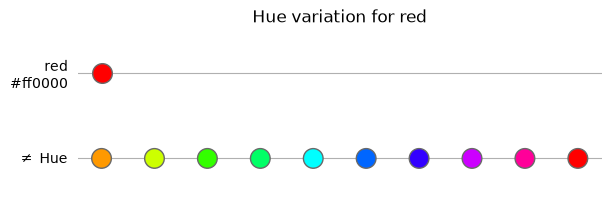

In [7]:
color = 'red'
hue_variation = compute_color_variation(color,'hue')

color_list_name = [color,r"$\neq$ Hue"]
colors_lists = [[color], hue_variation]

show_color(colors_lists,color_list_name,title=f"Hue variation for {color}")
plt.show()

Let's go back to the colors "Yellow" and "Y", which looked different to the eye.
We will look at their numerical values.
Note that the difference between the two versions corresponds to a difference in brightness.
Both yellows have the same hue and the same saturation, but one is darker than the other.

In [8]:
def get_color(color):
    rgb = mpl.colors.to_rgb(color)
    return (rgb,mpl.colors.to_hex(color),mpl.colors.rgb_to_hsv(rgb))

yellow_rgb, yellow_hex, yellow_hsv = get_color("yellow")
y_rgb, y_hex, y_hsv = get_color("y")

print(f"Yellow RGB : {yellow_rgb},   Yellow hex : {yellow_hex}")
print(f"With y RGB : {y_rgb}, with y hex : {y_hex}\n")
print("Comparing HSV between Yellow and y")
print(f"Yellow Hue : {yellow_hsv[0]:.3f} Saturation : {yellow_hsv[1]}, Brightness : {yellow_hsv[2]}")
print(f"With y Hue : {y_hsv[0]:.3f} Saturation : {y_hsv[1]}, Brightness : {y_hsv[2]}")


Yellow RGB : (1.0, 1.0, 0.0),   Yellow hex : #ffff00
With y RGB : (0.75, 0.75, 0.0), with y hex : #bfbf00

Comparing HSV between Yellow and y
Yellow Hue : 0.167 Saturation : 1.0, Brightness : 1.0
With y Hue : 0.167 Saturation : 1.0, Brightness : 0.75


We now display different brightness variations for the two "yellows".
We can see that the two variation scales are identical.
We also note that the concept of dark yellow is not very relevant... As soon as we darken it, "yellow" is no longer really "yellow".

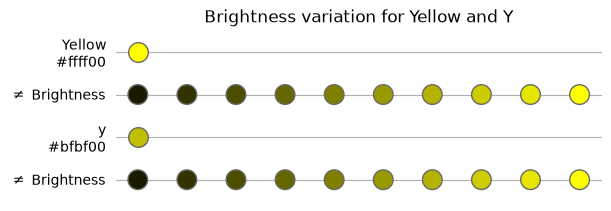

In [9]:
yellow_color = 'yellow'
y_color = 'y'

yellow_val = compute_color_variation(yellow_color,'val')
y_val = compute_color_variation(y_color,'val')

color_list_name = ['Yellow',r'$\neq$ Brightness','y',r'$\neq$ Brightness']
color_list = [[yellow_color],yellow_val,[y_color],y_val]

show_color(color_list,color_list_name,title="Brightness variation for Yellow and Y")
plt.show()

Another example to better visualize the concept of saturation. The color goes from the palest to the most vivid.

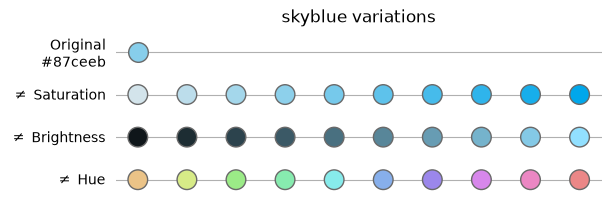

In [10]:
color = 'skyblue'

color_sat = compute_color_variation(color,'sat')
color_val = compute_color_variation(color,'val')
color_hue = compute_color_variation(color,'hue')

color_list_name = ['Original',r'$\neq$ Saturation',r'$\neq$ Brightness',r'$\neq$ Hue']
color_list = [[color],color_sat,color_val,color_hue]

show_color(color_list,color_list_name,title=f"{color} variations")
plt.show()

A complementary color is the original color with the opposite hue.
Hues are normally expressed in degrees on a color wheel, so the opposite hue is obvious in that case.
In Matplotlib, the hue is a number between 0 and 1 (red is the origin).
To get the opposite hue, we add 0.5 modulo 1 to the original hue.

Below are a few colors and their complementary colors.

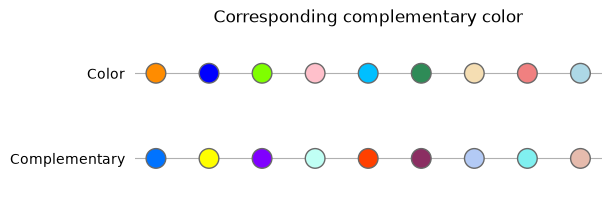

In [11]:
sample_color = ['darkorange','blue','chartreuse','pink','deepskyblue','seagreen','wheat','lightcoral','lightblue']
complementary_color = [get_complementary_color(color) for color in sample_color]

color_list_name = ['Color','Complementary']
color_list = [sample_color,complementary_color]

show_color(color_list,color_list_name,title="Corresponding complementary color")
plt.show()

To finish with color representation, here is a small mix of brightness and saturation variations for a color and its complementary color.

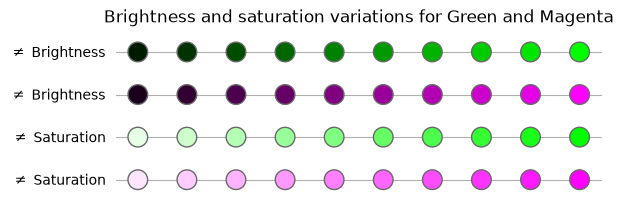

In [12]:
color = '#0f0'
complement_color = get_complementary_color(color)

color_sat = compute_color_variation(color,'sat')
complement_sat = compute_color_variation(complement_color,'sat')
color_bright = compute_color_variation(color,'val')
complement_bright = compute_color_variation(complement_color,'val')

color_list_name = [r'$\neq$ Brightness',r'$\neq$ Brightness',r'$\neq$ Saturation',r'$\neq$ Saturation']
color_list = [color_bright,complement_bright,color_sat,complement_sat]

show_color(color_list,color_list_name,title="Brightness and saturation variations for Green and Magenta")
plt.show()

## B - Colormaps

A colormap is a mapping that associates a color with a number between 0 and 1.
For example, a colormap could associate the RGB color (1,0,0) (red) with the number 0.3.
There are two types of colormaps: ListedColormap and LinearSegmentedColormap.

Below is a function that will help us visualize colormaps.

In [13]:
def draw_color_map(input_cmap):
    """
    Draw specified colormap.
    input_cmap may be a colormap instance or a string (name) of an already known one"""

    num_points = 256

    if isinstance(input_cmap,str) == True:
        cmap = mpl.colormaps[input_cmap]
        name = input_cmap
    else :
        cmap = input_cmap
        name = cmap.name

    grad = np.linspace(0, 1, num_points)
    grad = np.vstack((grad,grad))
    
    # set figure bar size in 100*pix
    fig_width, fig_height   = 6.4, 0.8
   
    fig, ax = plt.subplots(nrows=1, figsize=(fig_width, fig_height))
    plt.imshow(grad,aspect='auto',cmap=cmap)

    ax.set_title(f"{name}", fontsize=13)
    ax.set_yticks([])
    ax.set_xlabel("Input value")

    num_colors_threeshold = 6
    if (cmap.__class__.__name__ == "ListedColormap") & (cmap.N <= num_colors_threeshold):
        numcolors = cmap.N
    else:
        numcolors = num_colors_threeshold

    xticks_position = [val for val in np.linspace(0,255,numcolors+1)]
    xticks_raw_labels = np.linspace(0,1,numcolors+1)
    xticks_labels = np.round(xticks_raw_labels,2)
    
    ax.set_xticks(xticks_position,xticks_labels)  



### 1 - Listed colormap

A listed colormap is simply defined by the list of colors it contains.
A lookup table will be created to associate numbers with colors.
This mapping is done automatically if nothing is specified.

Below, we create a ListedColormap with 6 colors. We only provide the colors we want.
As you can see, colors can be specified in different ways (name, hex value, RGB tuple...).
Since the corresponding values are not provided, Matplotlib divides the interval [0,1] into 6 equal parts to build the mapping.

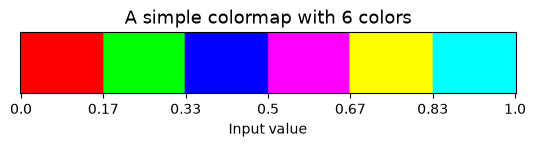

In [14]:
simple_colorlist = ['red', '#0f0', 'blue','magenta',(1.0,1.0,0.0),'cyan']

simple_cmap = ListedColormap(simple_colorlist,name="A simple colormap with 6 colors")

draw_color_map(simple_cmap)

Below, we display the different colors obtained depending on the value provided.

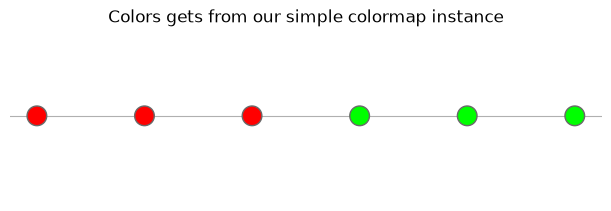

In [15]:
colors = [simple_cmap(0),simple_cmap(0.1),simple_cmap(0.16),simple_cmap(0.17),simple_cmap(0.2),simple_cmap(0.3)]
color_list = [colors]
show_color(color_list,[""],title="Colors gets from our simple colormap instance")
plt.show()

Matplotlib has several colormaps already defined internally. They can be used directly by specifying their name.

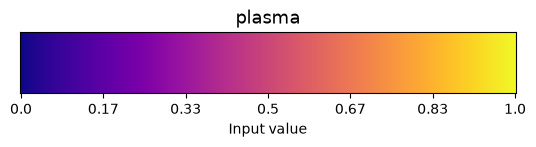

In [16]:
plasma_cmap = mpl.colormaps["plasma"]
draw_color_map(plasma_cmap)

A colormap can be modified by reducing its number of colors.

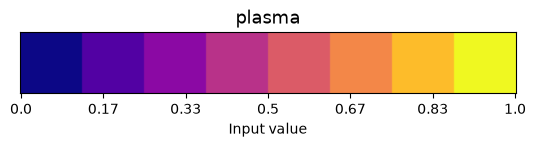

In [17]:
plasma_cmap =  mpl.colormaps['plasma'].resampled(8)
draw_color_map(plasma_cmap)

We can also modify only some of the colors of an existing colormap,
for example to give better visibility to certain values.

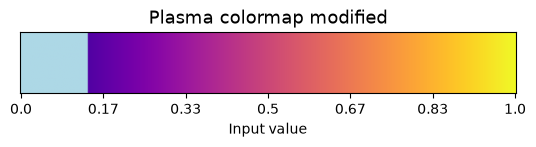

In [18]:
plasma_cmap = mpl.colormaps["plasma"]
light_blue = np.array(mpl.colors.to_rgb("lightblue"))

new_colors = np.array(plasma_cmap.colors)
new_colors[:35,:] = light_blue

plasma_new_cmap = ListedColormap(new_colors,name="Plasma colormap modified")

draw_color_map(plasma_new_cmap)

Among other things, a colormap can be used when plotting curves.

On the interval from 0 to $\pi$/2, the sine function takes values between 0 and 1.
The colormap will therefore associate each value of sin x with a color.

If we then plot the function on the interval from $-\pi$/2 to $\pi$/2, the values obtained for sin x range from -1 to 1.
What will happen?

In [19]:
PI = np.pi
PI_OVER_TWO = PI/2

num_points = 401
x_large = np.linspace(-PI_OVER_TWO,PI_OVER_TWO,num_points)
x_small = x_large[num_points//2:]

y_large = np.sin(x_large)
y_small = np.sin(x_small)

x_ticks_position = np.linspace(-PI_OVER_TWO,PI_OVER_TWO,5)
x_ticks_labels = [r"-$\pi$/2",r"-$\pi$/4","0",r"$\pi$/4",r"$\pi$/2"]

fig_width = 8.0
fig_height = 3.5

We will use our simple colormap, but with 5 colors.

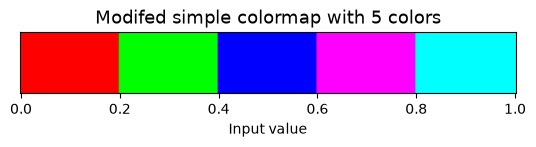

In [20]:
simple_colorlist = ['red', '#0f0', 'blue','magenta',"cyan"]
simple_cmap = ListedColormap(simple_colorlist,name="Modifed simple colormap with 5 colors")
draw_color_map(simple_cmap)

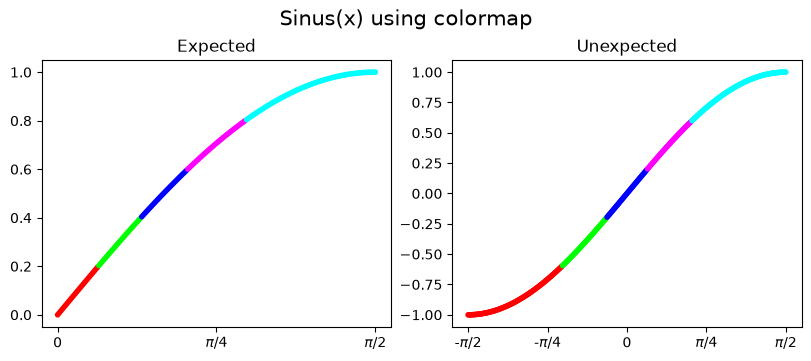

In [21]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(fig_width, fig_height),constrained_layout=True)

ax[0].scatter(x_small,y_small,c=y_small,marker='.',cmap=simple_cmap)
ax[0].set_title("Expected")

ax[0].set_xticks(x_ticks_position[2:],labels=x_ticks_labels[2:])
ax[0].set_yticks(np.linspace(0,1,6))

ax[1].set_xticks(x_ticks_position,labels=x_ticks_labels)
ax[1].set_yticks(np.linspace(-1,1,9))


ax[1].scatter(x_large,y_large,c=y_large,marker='.',cmap=simple_cmap)
ax[1].set_title("Unexpected")

fig.suptitle("Sinus(x) using colormap", fontsize=15)
plt.show()    

On the left figure we get the expected behavior. The points are displayed with the color defined in the colormap. On the right, however, we do get the full range of colors, but over the interval [-1,1].
In fact, Matplotlib normalized the values in order to use the entire range of available colors.

If we do not want this automatic mode, we can specify colors for values below the range, above the range, and for bad values.

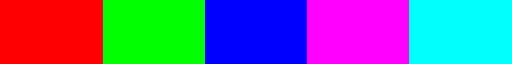

In [22]:
bad_color = "black"
under_color = "orange"
over_color = "pink"

simple_cmap = simple_cmap.with_extremes(bad=bad_color, under=under_color, over=over_color)
simple_cmap

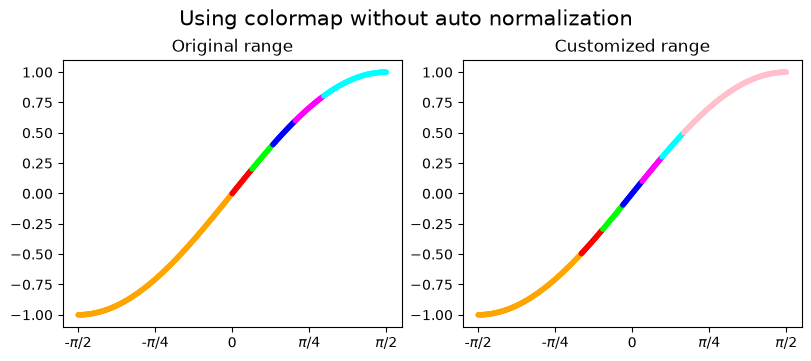

In [23]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(fig_width, fig_height),constrained_layout=True)

norm = mpl.colors.Normalize(vmin=0, vmax=1.0, clip=False)
ax[0].scatter(x_large,y_large,c=y_large,marker='.',cmap=simple_cmap,norm=norm)
ax[0].set_title("Original range")
ax[0].set_xticks(x_ticks_position,labels=x_ticks_labels)
ax[0].set_yticks(np.linspace(-1,1,9))

norm = mpl.colors.Normalize(vmin=-0.5, vmax=0.5, clip=False)
ax[1].scatter(x_large,y_large,c=y_large,marker='.',cmap=simple_cmap,norm=norm)
ax[1].set_title("Customized range")
ax[1].set_xticks(x_ticks_position,labels=x_ticks_labels)
ax[1].set_yticks(np.linspace(-1,1,9))

fig.suptitle("Using colormap without auto normalization", fontsize=15)

plt.show()    

On the left figure, we restored the initial range and the under color is used.
On the right figure, we set a custom range and we get values both above and below it.

### 2 - LinearSegmentedColormap

Here too we provide a list of colors, but the colormap is determined by computing gradients (linear interpolation) between these colors.

We will specify four colors that we will use to build our LinearSegmentedColormap.

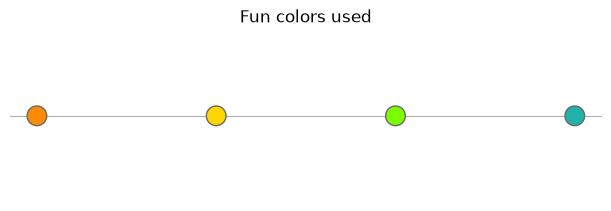

In [24]:
fun_colors_list = ["darkorange", "gold", "lawngreen", "lightseagreen"]
show_color([fun_colors_list],[""],title="Fun colors used")
plt.show()

The four specified colors are evenly distributed over the interval [0,1], then the gradients between each pair of colors are computed.

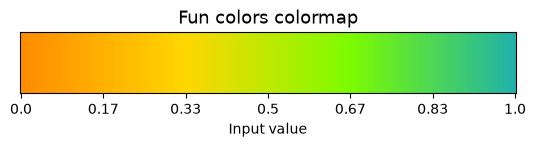

In [25]:
colors_cmap = LinearSegmentedColormap.from_list("Fun colors colormap",fun_colors_list)
draw_color_map(colors_cmap)

We can choose the position of the original colors. This gives another colormap based on the same colors as before.

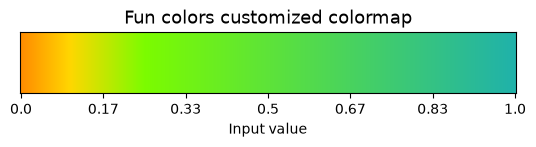

In [26]:
fun_color2_cmap = LinearSegmentedColormap.from_list("Fun colors customized colormap",
    [(0.0,"darkorange"),(0.1,"gold"),(0.25,"lawngreen"),(1.0,"lightseagreen")])
draw_color_map(fun_color2_cmap)

As with ListedColormaps, there are colormaps already defined in Matplotlib.

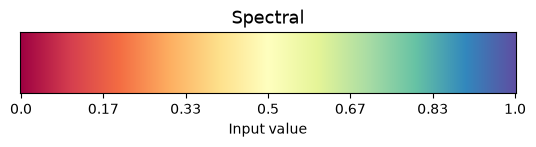

In [27]:
spect_cmap = plt.get_cmap("Spectral")
draw_color_map(spect_cmap)

We can also choose the number of output colors (256 by default).
This makes it possible to recover the behavior of ListedColormaps, by using a small number of colors while still computing the gradient between two colors.

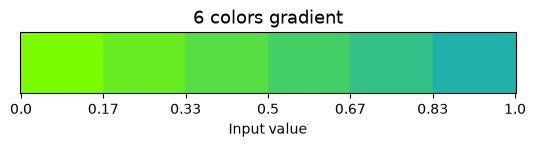

In [28]:
colors_list = ["lawngreen","lightseagreen"]
grad_cmap = LinearSegmentedColormap.from_list("6 colors gradient", colors_list,N=6)
draw_color_map(grad_cmap)

# Conclusion

There would still be a lot to say about colors in general and how they can be used in Matplotlib. Don't hesitate to dig into the official documentation.